# Lazy Note: End-to-End Audio Ingestion & DSP Conditioning Pipeline
### Testing Sandbox: Live Recording $\rightarrow$ WebM Byte-Chunking $\rightarrow$ Simulated Upload $\rightarrow$ Binary Master Reassembly $\rightarrow$ Linear STT DSP $\rightarrow$ Silero VAD Compaction

**Objective:** validate the core Phase 1 audio milestones:
1. **Audio Capture:** browser mic widget (WebRTC AGC / noise suppression / echo cancellation **disabled**, Opus 32 kbps WebM) or classroom sample `conv1.m4a`.
2. **Edge Transport Chunking:** the stream is encoded to WebM/Opus and sliced at the **raw byte level**, like `MediaRecorder.start(timeslice)`: only `chunk_0000` carries the EBML header.
3. **Simulated Server Ingestion:** sequential upload, SHA-256 + sequence verification.
4. **Master Remuxing:** byte-concatenate verified chunks, then `ffmpeg -c copy -fflags +genpts` to rebuild an immutable, seekable master.
5. **Linear STT DSP Chain:** deterministic filters only (highpass, 50/100 Hz notch, adeclick, speechnorm, lowpass). No F0 tracking or formant EQ, since spectral reshaping tends to hurt neural ASR.
6. **Silero VAD Compaction:** prune silences > 2.5 s, build a `TimestampOffsetMap`, emit ~10-minute pause-aligned slices.
7. **"What Are We Getting?" Analysis:** waveforms, spectrograms, level / rumble metrics, VAD savings.


In [15]:
import os
import sys
import json
import time
import math
import wave
import struct
import shutil
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display, HTML

# 1. Verify FFmpeg & FFprobe
def check_binary(binary_name):
    path = shutil.which(binary_name)
    if not path:
        raise RuntimeError(f"Required binary '{binary_name}' was not found on PATH.")
    ver = subprocess.run([binary_name, "-version"], capture_output=True, text=True).stdout.splitlines()[0]
    print(f"\u2705 Found {binary_name}: {ver}")

check_binary("ffmpeg")
check_binary("ffprobe")

# 2. Directory setup
NOTEBOOK_DIR = Path.cwd()
SAMPLE_DIR = NOTEBOOK_DIR / "sample"
RESULT_DIR = NOTEBOOK_DIR / "result" / "pipeline_test"
CHUNKS_DIR = RESULT_DIR / "client_chunks"
SERVER_DIR = RESULT_DIR / "server_storage"

for d in [RESULT_DIR, CHUNKS_DIR, SERVER_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"\n\U0001f4c1 Output sandbox initialized at: {RESULT_DIR}")

✅ Found ffmpeg: ffmpeg version n9.0.2 Copyright (c) 2000-2026 the FFmpeg developers
✅ Found ffprobe: ffprobe version n9.0.2 Copyright (c) 2007-2026 the FFmpeg developers

📁 Output sandbox initialized at: /run/media/rtx/Files/Code/ProProjects/lazynote/backend/notebooks/result/pipeline_test


## 1. Audio Source Selection: Live Recording or Lecture Sample

- **Mode A (Preset Lecture Sample):** clip 60 s from `sample/conv1.m4a` (real classroom audio).
- **Mode B (Live Microphone Recording):** use the browser widget below. Browser DSP is disabled so far-field speech is not suppressed; output is WebM/Opus.


In [17]:
# Optional Interactive Browser Microphone Recorder (classroom-tuned: raw far-field, WebM/Opus 32 kbps)
# If skipped, the notebook falls back to 'sample/conv1.m4a'.
LIVE_AUDIO_FILE = RESULT_DIR / "live_recording.webm"

html_recorder = f"""
<div style="border: 1px solid #444; border-radius: 8px; padding: 16px; background: #1e1e2e; color: #fff; max-width: 520px;">
  <h4 style="margin-top: 0; color: #89b4fa;">🎤 Classroom Far-Field Audio Capture (Opus)</h4>
  <p style="font-size: 12px; color: #cdd6f4;">Browser AGC, noise suppression &amp; echo cancellation are <b>DISABLED</b> to preserve distant lecturer speech.</p>
  <button id="startBtn" style="background: #a6e3a1; color: #11111b; border: none; padding: 8px 16px; border-radius: 4px; font-weight: bold; cursor: pointer;">Start Recording</button>
  <button id="stopBtn" disabled style="background: #f38ba8; color: #11111b; border: none; padding: 8px 16px; border-radius: 4px; font-weight: bold; cursor: pointer; margin-left: 8px;">Stop Recording</button>
  <span id="recStatus" style="margin-left: 12px; font-size: 13px; color: #fab387;">Idle</span>
  <div id="audioPreview" style="margin-top: 12px;"></div>
</div>

<script>
(function() {{
  let mediaRecorder;
  let audioChunks = [];
  const startBtn = document.getElementById('startBtn');
  const stopBtn = document.getElementById('stopBtn');
  const recStatus = document.getElementById('recStatus');
  const preview = document.getElementById('audioPreview');

  startBtn.onclick = async () => {{
    try {{
      const stream = await navigator.mediaDevices.getUserMedia({{
        audio: {{
          channelCount: 1,
          sampleRate: 16000,   // a hint only; browsers may still capture at 48 kHz
          echoCancellation: false,
          noiseSuppression: false,
          autoGainControl: false
        }}
      }});
      const mimeType = MediaRecorder.isTypeSupported('audio/webm;codecs=opus')
        ? 'audio/webm;codecs=opus'
        : 'audio/webm';

      mediaRecorder = new MediaRecorder(stream, {{ mimeType: mimeType, audioBitsPerSecond: 32000 }});
      audioChunks = [];
      mediaRecorder.ondataavailable = e => {{
        if (e.data && e.data.size > 0) audioChunks.push(e.data);
      }};
      mediaRecorder.onstop = async () => {{
        const audioBlob = new Blob(audioChunks, {{ type: mimeType }});
        const reader = new FileReader();
        reader.readAsDataURL(audioBlob);
        reader.onloadend = () => {{
          const base64data = reader.result.split(',')[1];
          if (window.IPython && IPython.notebook && IPython.notebook.kernel) {{
            IPython.notebook.kernel.execute(
              `import base64; from pathlib import Path; Path('{LIVE_AUDIO_FILE}').write_bytes(base64.b64decode('${{base64data}}'))`
            );
          }}
          preview.innerHTML = `<audio controls src="${{reader.result}}" style="width: 100%; margin-top: 8px;"></audio><p style="color:#a6e3a1; font-size:12px;">\u2714 Captured as WebM/Opus ({LIVE_AUDIO_FILE.name}).</p>`;
          recStatus.textContent = 'Saved to notebook!';
        }};
        stream.getTracks().forEach(t => t.stop());
      }};
      // 5 s transport slices in the sandbox (30 s in production)
      mediaRecorder.start(5000);
      startBtn.disabled = true;
      stopBtn.disabled = false;
      recStatus.textContent = '🔴 Recording (5s transport slices)...';
    }} catch(err) {{
      recStatus.textContent = 'Error: ' + err.message;
    }}
  }};

  stopBtn.onclick = () => {{
    if (mediaRecorder && mediaRecorder.state !== 'inactive') {{
      mediaRecorder.stop();
      startBtn.disabled = false;
      stopBtn.disabled = true;
      recStatus.textContent = 'Processing...';
    }}
  }};
}})();
</script>
"""
display(HTML(html_recorder))


In [18]:
# Prepare Raw Input Audio (Extract 60 seconds from sample/conv1.m4a or use live audio)
RAW_INPUT_FILE = RESULT_DIR / "raw_input.wav"

if LIVE_AUDIO_FILE.exists() and LIVE_AUDIO_FILE.stat().st_size > 1000:
    print(f"\u2705 Using live recorded audio: {LIVE_AUDIO_FILE}")
    # Decode live WebM/Opus straight to 16 kHz mono PCM (the rate STT & VAD use natively)
    cmd = ["ffmpeg", "-y", "-i", str(LIVE_AUDIO_FILE), "-ar", "16000", "-ac", "1", "-c:a", "pcm_s16le", str(RAW_INPUT_FILE)]
    subprocess.run(cmd, capture_output=True, check=True)
else:
    sample_file = SAMPLE_DIR / "conv1.m4a"
    if not sample_file.exists():
        raise FileNotFoundError(f"Sample audio not found at {sample_file}")
    
    print(f"\U0001f4e6 Loading sample lecture audio: {sample_file}")
    # Extract 60 seconds (from 00:10 to 01:10) to give a solid multi-chunk test segment
    cmd = [
        "ffmpeg", "-y",
        "-ss", "00:00:10",
        "-i", str(sample_file),
        "-t", "60",
        "-ar", "16000", "-ac", "1", "-c:a", "pcm_s16le",
        str(RAW_INPUT_FILE)
    ]
    subprocess.run(cmd, capture_output=True, check=True)

# Inspect raw input audio with ffprobe
probe_cmd = [
    "ffprobe", "-v", "error",
    "-show_entries", "format=duration,size,bit_rate:stream=sample_rate,channels,codec_name",
    "-of", "json",
    str(RAW_INPUT_FILE)
]
probe_res = subprocess.run(probe_cmd, capture_output=True, text=True, check=True)
probe_info = json.loads(probe_res.stdout)
raw_duration = float(probe_info['format']['duration'])
raw_sr = int(probe_info['streams'][0]['sample_rate'])
raw_ch = int(probe_info['streams'][0]['channels'])
raw_codec = probe_info['streams'][0]['codec_name']

print(f"\U0001f3b5 Raw Input Ready: {RAW_INPUT_FILE.name}")
print(f"   Duration:    {raw_duration:.2f} seconds ({raw_duration/60:.2f} mins)")
print(f"   Sample Rate: {raw_sr} Hz, Channels: {raw_ch}, Codec: {raw_codec}")
print(f"   File Size:   {RAW_INPUT_FILE.stat().st_size / (1024*1024):.2f} MB")

display(Audio(str(RAW_INPUT_FILE)))

📦 Loading sample lecture audio: /run/media/rtx/Files/Code/ProProjects/lazynote/backend/notebooks/sample/conv1.m4a
🎵 Raw Input Ready: raw_input.wav
   Duration:    60.00 seconds (1.00 mins)
   Sample Rate: 16000 Hz, Channels: 1, Codec: pcm_s16le
   File Size:   1.83 MB


## 2. Edge Transport Chunking (Simulating Browser Client)

In the Lazy Note architecture:
- The edge client (`MediaRecorder` with a `timeslice`) emits sequential transport chunks, stored in IndexedDB / OPFS and uploaded with `seq_no`.
- **Real container behaviour:** only `chunk_0` has the EBML/Matroska header; `chunk_1..N` are headerless cluster bytes. They are **not** independently decodable and **cannot** go through FFmpeg's `concat` demuxer.
- This cell therefore encodes the sample to a continuous 32 kbps mono WebM/Opus stream and slices it at **raw byte offsets**. The server must reassemble by binary concatenation.


In [19]:
# Simulate MediaRecorder WebM/Opus transport chunks (raw byte slicing)
CHUNK_SIZE_BYTES = 40_000  # ~10 s of 32 kbps Opus (production: ~120 KB for 30 s)
SIM_STREAM_FILE = RESULT_DIR / "simulated_browser_stream.webm"

# 1. Encode the raw input into the stream a browser would produce
subprocess.run([
    "ffmpeg", "-y", "-i", str(RAW_INPUT_FILE),
    "-ar", "48000", "-ac", "1", "-c:a", "libopus", "-b:a", "32k",
    str(SIM_STREAM_FILE)
], check=True, capture_output=True)

# Clear previous test chunks
for f in CHUNKS_DIR.glob("chunk_*"):
    f.unlink()

stream_bytes = SIM_STREAM_FILE.read_bytes()
SIM_STREAM_SHA256 = hashlib.sha256(stream_bytes).hexdigest()
chunks_metadata = []

for i, offset in enumerate(range(0, len(stream_bytes), CHUNK_SIZE_BYTES)):
    chunk_name = f"chunk_{i:04d}.webm"
    chunk_path = CHUNKS_DIR / chunk_name
    payload = stream_bytes[offset: offset + CHUNK_SIZE_BYTES]
    chunk_path.write_bytes(payload)
    chunks_metadata.append({
        "chunk_id": f"chk_{i:04d}",
        "seq_no": i,
        "filename": chunk_name,
        "local_path": str(chunk_path),
        "byte_offset": offset,
        "byte_size": len(payload),
        "sha256": hashlib.sha256(payload).hexdigest(),
    })

print(f"\U0001f4e6 Stream: {SIM_STREAM_FILE.name} ({len(stream_bytes)/1024:.1f} KB, "
      f"{len(stream_bytes)*8/raw_duration/1000:.1f} kbps avg)")
print(f"\u2702\ufe0f Emitted {len(chunks_metadata)} byte-level chunks (only chunk_0000 has the EBML header):")
print(f"{'Seq':<5} | {'Filename':<18} | {'Byte offset':<12} | {'Size':<10} | {'Starts with EBML?':<18} | {'SHA-256 (prefix)':<18}")
print("-" * 95)
for m in chunks_metadata:
    head = Path(m["local_path"]).read_bytes()[:4] == b"\x1a\x45\xdf\xa3"
    print(f"{m['seq_no']:<5} | {m['filename']:<18} | {m['byte_offset']:<12} | {m['byte_size']/1024:>6.1f} KB | {str(head):<18} | {m['sha256'][:16]}...")


📦 Stream: simulated_browser_stream.webm (237.5 KB, 32.4 kbps avg)
✂️ Emitted 7 byte-level chunks (only chunk_0000 has the EBML header):
Seq   | Filename           | Byte offset  | Size       | Starts with EBML?  | SHA-256 (prefix)  
-----------------------------------------------------------------------------------------------
0     | chunk_0000.webm    | 0            |   39.1 KB | True               | 9913d45c52baf415...
1     | chunk_0001.webm    | 40000        |   39.1 KB | False              | be5cc29234528960...
2     | chunk_0002.webm    | 80000        |   39.1 KB | False              | f55f9a14314f97b2...
3     | chunk_0003.webm    | 120000       |   39.1 KB | False              | a2ace316d67c278b...
4     | chunk_0004.webm    | 160000       |   39.1 KB | False              | 8654436e1e3a767e...
5     | chunk_0005.webm    | 200000       |   39.1 KB | False              | cba8e3e3d744b0a5...
6     | chunk_0006.webm    | 240000       |    3.1 KB | False              | ed8c1fbb0dd2

## 3. Simulated Server Ingestion & Network Upload

In production:
- Chunks are uploaded via `POST /api/v1/sessions/{session_id}/chunks` with the raw WebM bytes and header metadata (`seq_no`, `sha256`).
- Each chunk is an opaque byte block, not a playable file, so the server never decodes it at this stage.
- The server verifies the payload checksum and sequence continuity, then stores the chunk on disk or Cloudflare R2. In this sandbox a sequence gap only prints a warning; the finalize step (section 4) hard-fails on any gap.
- PostgreSQL registers the chunk row with `is_verified = true`.


In [20]:
# Simulated FastAPI Server Ingestion Service
class SimulatedUploadServer:
    def __init__(self, storage_dir: Path):
        self.storage_dir = storage_dir
        self.database = {}  # session_id -> list of verified chunks
        
    def upload_chunk(self, session_id: str, file_path: Path, metadata: dict) -> dict:
        """Simulates FastAPI POST /api/v1/sessions/{id}/chunks"""
        # 1. Simulate network transmission latency (e.g. 20ms)
        time.sleep(0.02)
        
        # 2. Read incoming payload and verify checksum
        payload = file_path.read_bytes()
        computed_hash = hashlib.sha256(payload).hexdigest()
        if computed_hash != metadata["sha256"]:
            return {"status": "error", "error": "Checksum mismatch! Corrupted transfer."}
        
        # 3. Verify sequence continuity
        if session_id not in self.database:
            self.database[session_id] = []
        expected_seq = len(self.database[session_id])
        if metadata["seq_no"] != expected_seq:
            print(f"   \u26a0\ufe0f Sequence gap: got {metadata['seq_no']}, expected {expected_seq}")
        
        # 4. Save to server storage repository
        server_chunk_path = self.storage_dir / f"{session_id}_{metadata['filename']}"
        server_chunk_path.write_bytes(payload)
        
        record = {
            **metadata,
            "server_path": str(server_chunk_path),
            "is_verified": True,
            "received_at": time.time()
        }
        self.database[session_id].append(record)
        return {"status": "success", "http_status": 201, "record": record}

# Run upload simulation
server = SimulatedUploadServer(SERVER_DIR)
SESSION_ID = "sess_demo_101"

print(f"\U0001f680 Uploading {len(chunks_metadata)} chunks to server (Session: {SESSION_ID})...")
upload_start = time.time()
for m in chunks_metadata:
    resp = server.upload_chunk(SESSION_ID, Path(m["local_path"]), m)
    rec = resp["record"]
    print(f"  \u27a1\ufe0f Uploaded {rec['filename']} -> HTTP {resp['http_status']} (Verified: {rec['is_verified']})")

upload_duration = (time.time() - upload_start) * 1000
print(f"\n\u2705 All chunks uploaded & verified on server in {upload_duration:.1f}ms.")

🚀 Uploading 7 chunks to server (Session: sess_demo_101)...
  ➡️ Uploaded chunk_0000.webm -> HTTP 201 (Verified: True)
  ➡️ Uploaded chunk_0001.webm -> HTTP 201 (Verified: True)
  ➡️ Uploaded chunk_0002.webm -> HTTP 201 (Verified: True)
  ➡️ Uploaded chunk_0003.webm -> HTTP 201 (Verified: True)
  ➡️ Uploaded chunk_0004.webm -> HTTP 201 (Verified: True)
  ➡️ Uploaded chunk_0005.webm -> HTTP 201 (Verified: True)
  ➡️ Uploaded chunk_0006.webm -> HTTP 201 (Verified: True)

✅ All chunks uploaded & verified on server in 157.1ms.


## 4. Server-Side Master Remuxing & Verification

Once the lecture ends (`POST /finalize`):
- The server verifies sequence continuity (0..N, no gaps) and each chunk's SHA-256.
- Chunks are **binary-concatenated** in order (`shutil.copyfileobj`). FFmpeg's concat demuxer can't be used, because headerless chunks are not standalone files.
- A lossless remux (`-c copy -fflags +genpts`) rebuilds duration metadata and the Cues index, giving a seekable immutable master (`master_raw.webm`).
- The concatenated bytes are compared against the original stream, and duration is checked with `ffprobe`.


In [22]:
# Master Remuxing: verified binary concatenation + lossless FFmpeg remux
MASTER_RAW_FILE = RESULT_DIR / "master_raw.webm"
CONCAT_TMP_FILE = RESULT_DIR / "master_concat_tmp.webm"

session_chunks = sorted(server.database[SESSION_ID], key=lambda x: x["seq_no"])

# 1. Sequence continuity
seqs = [c["seq_no"] for c in session_chunks]
if seqs != list(range(len(seqs))):
    raise ValueError(f"Sequence gap detected on server: {seqs}")

# 2. Verify checksums + binary concatenation
remux_start = time.time()
with open(CONCAT_TMP_FILE, "wb") as out_f:
    for c in session_chunks:
        server_file = Path(c["server_path"])
        if not server_file.exists():
            raise FileNotFoundError(f"Missing transport chunk: {c['filename']}")
        if hashlib.sha256(server_file.read_bytes()).hexdigest() != c["sha256"]:
            raise ValueError(f"Checksum mismatch on {c['filename']}")
        with open(server_file, "rb") as in_f:
            shutil.copyfileobj(in_f, out_f)

concat_identical = hashlib.sha256(CONCAT_TMP_FILE.read_bytes()).hexdigest() == SIM_STREAM_SHA256
print(f"\U0001f9e9 Binary concat of {len(session_chunks)} chunks identical to original stream: {concat_identical}")

# 3. Lossless remux (fixes duration metadata, builds seekable Cues index)
subprocess.run([
    "ffmpeg", "-y", "-fflags", "+genpts",
    "-i", str(CONCAT_TMP_FILE),
    "-c", "copy",
    str(MASTER_RAW_FILE)
], check=True, capture_output=True, text=True)
remux_duration = (time.time() - remux_start) * 1000
CONCAT_TMP_FILE.unlink(missing_ok=True)

# 4. Probe master
master_probe = json.loads(subprocess.run([
    "ffprobe", "-v", "error",
    "-show_entries", "format=duration,size:stream=sample_rate,channels,codec_name",
    "-of", "json", str(MASTER_RAW_FILE)
], capture_output=True, text=True, check=True).stdout)
master_duration = float(master_probe['format']['duration'])

print(f"\u2705 Master Remux Complete in {remux_duration:.1f}ms!")
print(f"   Original Raw Duration:       {raw_duration:.2f}s")
print(f"   Reassembled Master Duration: {master_duration:.2f}s")
print(f"   Duration Delta:              {abs(master_duration - raw_duration):.4f}s")
print(f"   Master File Size:            {MASTER_RAW_FILE.stat().st_size / 1024:.1f} KB")
print(f"   Sample Rate: {master_probe['streams'][0]['sample_rate']} Hz, Channels: {master_probe['streams'][0]['channels']}, Codec: {master_probe['streams'][0]['codec_name']}")

display(Audio(str(MASTER_RAW_FILE)))


🧩 Binary concat of 7 chunks identical to original stream: True
✅ Master Remux Complete in 117.9ms!
   Original Raw Duration:       60.00s
   Reassembled Master Duration: 60.01s
   Duration Delta:              0.0071s
   Master File Size:            237.5 KB
   Sample Rate: 48000 Hz, Channels: 1, Codec: opus


## 5. Linear STT DSP Filter Chain (FFmpeg)

A deterministic chain with no pitch tracking and no formant/presence EQ. Neural ASR encoders expect the natural spectral envelope, so the chain only removes things that are clearly not speech:
1. **`highpass=f=85:poles=2`**: strips fan/AC rumble and handling thumps.
2. **`equalizer=f=50` / `f=100` notches**: remove 50 Hz mains hum and its 2nd harmonic.
3. **`adeclick=w=55:o=75:t=2.5`**: interpolates pen clicks and desk taps.
4. **`speechnorm=e=6.25:r=0.0001:l=1`**: gently levels far-field volume drops.
5. **`lowpass=f=7600:poles=2`**: anti-alias roll-off before the 8 kHz Nyquist limit.
6. **Output:** 16 kHz mono `pcm_s16le`.

The removed steps were the F0 autocorrelation profiler, the 1.5-3.5 kHz presence boost, the 320 Hz cut, `afftdn` and `dynaudnorm`.


In [23]:
# 1. Helper to read raw PCM audio into a numpy float array
def load_wav_pcm(filepath: Path):
    with wave.open(str(filepath), 'rb') as wf:
        n_channels = wf.getnchannels()
        sampwidth = wf.getsampwidth()
        framerate = wf.getframerate()
        raw_bytes = wf.readframes(wf.getnframes())
        if sampwidth != 2:
            raise ValueError(f"Unsupported sample width: {sampwidth}")
        audio_data = np.frombuffer(raw_bytes, dtype=np.int16).astype(np.float32)
        if n_channels > 1:
            audio_data = audio_data.reshape(-1, n_channels)[:, 0]
        return audio_data / 32768.0, framerate


# 2. Deterministic linear DSP chain
STT_FILTER_CHAIN = (
    "highpass=f=85:poles=2,"
    "equalizer=f=50:t=q:w=10:g=-25,"
    "equalizer=f=100:t=q:w=10:g=-15,"
    "adeclick=w=55:o=75:t=2.5,"
    "speechnorm=e=6.25:r=0.0001:l=1,"
    "lowpass=f=7600:poles=2"
)

def run_stt_linear_dsp_chain(master_audio_path: Path, output_pcm_wav: Path) -> Path:
    subprocess.run([
        "ffmpeg", "-y",
        "-i", str(master_audio_path),
        "-af", STT_FILTER_CHAIN,
        "-ar", "16000", "-ac", "1",
        "-c:a", "pcm_s16le",
        str(output_pcm_wav)
    ], check=True, capture_output=True)
    return output_pcm_wav


DSP_CONDITIONED_FILE = RESULT_DIR / "dsp_conditioned.wav"
print(f"\U0001f39b\ufe0f Filter Chain: {STT_FILTER_CHAIN}")

dsp_start = time.time()
run_stt_linear_dsp_chain(MASTER_RAW_FILE, DSP_CONDITIONED_FILE)
dsp_duration = (time.time() - dsp_start) * 1000

dsp_probe = json.loads(subprocess.run([
    "ffprobe", "-v", "error",
    "-show_entries", "format=duration,size:stream=sample_rate,channels,codec_name",
    "-of", "json", str(DSP_CONDITIONED_FILE)
], capture_output=True, text=True, check=True).stdout)

dsp_duration_sec = float(dsp_probe['format']['duration'])
dsp_sr = int(dsp_probe['streams'][0]['sample_rate'])
dsp_ch = int(dsp_probe['streams'][0]['channels'])

print(f"\u2705 Linear DSP Conditioning Complete in {dsp_duration:.1f}ms "
      f"({dsp_duration / 1000 / max(dsp_duration_sec, 1e-9):.3f}x real-time)")
print(f"   Output File:   {DSP_CONDITIONED_FILE.name}")
print(f"   Duration:      {dsp_duration_sec:.2f}s")
print(f"   Sample Rate:   {dsp_sr} Hz, Channels: {dsp_ch} (Mono)")
print(f"   Output Size:   {DSP_CONDITIONED_FILE.stat().st_size / (1024*1024):.2f} MB")

display(Audio(str(DSP_CONDITIONED_FILE)))


🎛️ Filter Chain: highpass=f=85:poles=2,equalizer=f=50:t=q:w=10:g=-25,equalizer=f=100:t=q:w=10:g=-15,adeclick=w=55:o=75:t=2.5,speechnorm=e=6.25:r=0.0001:l=1,lowpass=f=7600:poles=2
✅ Linear DSP Conditioning Complete in 1073.2ms (0.018x real-time)
   Output File:   dsp_conditioned.wav
   Duration:      60.00s
   Sample Rate:   16000 Hz, Channels: 1 (Mono)
   Output Size:   1.83 MB


## 5b. Silero VAD Compaction, `TimestampOffsetMap` & ~10-Min Pause-Aligned Slicing

- Silero VAD runs on the conditioned 16 kHz WAV. Gaps shorter than 2.5 s are bridged (natural pauses stay), longer gaps (e.g. board-writing) are dropped, and each segment keeps a 250 ms pad.
- A `TimestampOffsetMap` projects timestamps from the compacted audio back to original lecture wall-clock ms, so `TranscriptSegment.start_ms/end_ms` stay correct.
- Slices are flushed at the first speech boundary after ~10 minutes of compacted audio.
- Requires `torch` (Silero is fetched via `torch.hub` on first run, which needs network access).


In [25]:
from dataclasses import dataclass
import torch

@dataclass
class OffsetSegment:
    compacted_start_ms: int
    compacted_end_ms: int
    original_start_ms: int
    original_end_ms: int

class TimestampOffsetMap:
    """Projects timestamps from VAD-compacted audio back to original wall-clock ms."""
    def __init__(self, segments):
        self.segments = segments

    def to_original_ms(self, compacted_ms: int) -> int:
        for seg in self.segments:
            if seg.compacted_start_ms <= compacted_ms <= seg.compacted_end_ms:
                return seg.original_start_ms + (compacted_ms - seg.compacted_start_ms)
        for seg in reversed(self.segments):
            if compacted_ms >= seg.compacted_end_ms:
                return seg.original_end_ms
        return 0


def _write_pcm16_wav(path: Path, float_samples: np.ndarray, sr: int = 16000) -> None:
    pcm16 = np.clip(float_samples * 32768.0, -32768, 32767).astype(np.int16)
    with wave.open(str(path), "wb") as wf:
        wf.setnchannels(1)
        wf.setsampwidth(2)
        wf.setframerate(sr)
        wf.writeframes(pcm16.tobytes())


def run_silero_vad_compaction_and_slicing(
    conditioned_wav_path: Path,
    output_dir: Path,
    max_silence_ms: int = 2500,
    speech_pad_ms: int = 250,
    target_slice_sec: int = 600,
):
    model, utils = torch.hub.load(repo_or_dir="snakers4/silero-vad", model="silero_vad", trust_repo=True)
    get_speech_timestamps = utils[0]

    sr = 16000
    sig, file_sr = load_wav_pcm(conditioned_wav_path)
    assert file_sr == sr, f"VAD expects {sr} Hz, got {file_sr}"
    wav_tensor = torch.from_numpy(sig)
    total_samples = len(sig)
    orig_total_ms = int(round(total_samples * 1000.0 / sr))

    stamps = get_speech_timestamps(
        wav_tensor, model, sampling_rate=sr, threshold=0.45,
        min_speech_duration_ms=250, min_silence_duration_ms=max_silence_ms,
        speech_pad_ms=speech_pad_ms,
    )
    if not stamps:
        print("\u26a0\ufe0f No speech detected by VAD; returning original audio.")
        return [conditioned_wav_path], TimestampOffsetMap([OffsetSegment(0, orig_total_ms, 0, orig_total_ms)]), orig_total_ms

    for old in output_dir.glob("vad_slice_*.wav"):
        old.unlink()

    offset_segments, slice_files = [], []
    compacted_ms, slice_idx = 0, 0
    cur_samples, cur_sec = [], 0.0

    for st in stamps:
        seg = sig[st["start"]:st["end"]]
        seg_ms = int(round((st["end"] - st["start"]) * 1000.0 / sr))
        orig_start = int(round(st["start"] * 1000.0 / sr))
        offset_segments.append(OffsetSegment(compacted_ms, compacted_ms + seg_ms, orig_start, orig_start + seg_ms))
        compacted_ms += seg_ms
        cur_samples.append(seg)
        cur_sec += seg_ms / 1000.0
        if cur_sec >= target_slice_sec:
            p = output_dir / f"vad_slice_{slice_idx:03d}.wav"
            _write_pcm16_wav(p, np.concatenate(cur_samples), sr)
            slice_files.append(p); slice_idx += 1
            cur_samples, cur_sec = [], 0.0

    if cur_samples:
        p = output_dir / f"vad_slice_{slice_idx:03d}.wav"
        _write_pcm16_wav(p, np.concatenate(cur_samples), sr)
        slice_files.append(p)

    return slice_files, TimestampOffsetMap(offset_segments), compacted_ms


vad_start = time.time()
vad_slices, offset_map, compacted_total_ms = run_silero_vad_compaction_and_slicing(DSP_CONDITIONED_FILE, RESULT_DIR)
vad_duration = (time.time() - vad_start) * 1000

orig_total_ms = int(round(dsp_duration_sec * 1000))
vad_saved_pct = 100.0 * (1.0 - compacted_total_ms / max(1, orig_total_ms))
print(f"\u2702\ufe0f Silero VAD: {orig_total_ms/1000:.2f}s -> {compacted_total_ms/1000:.2f}s "
      f"({vad_saved_pct:.1f}% removed) | {len(offset_map.segments)} speech segment(s) | {len(vad_slices)} slice(s) | {vad_duration:.0f}ms")
print(f"{'#':<4} | {'Compacted (ms)':<22} | {'Original (ms)':<22}")
print("-" * 55)
for i, s in enumerate(offset_map.segments[:15]):
    print(f"{i:<4} | {s.compacted_start_ms:>8} - {s.compacted_end_ms:<10} | {s.original_start_ms:>8} - {s.original_end_ms:<10}")
if len(offset_map.segments) > 15:
    print(f"... ({len(offset_map.segments) - 15} more)")
if offset_map.segments:
    probe_ms = offset_map.segments[-1].compacted_end_ms // 2
    print(f"Round-trip example: compacted {probe_ms} ms -> original {offset_map.to_original_ms(probe_ms)} ms")
for p in vad_slices:
    print(f"   \U0001f4c4 {p.name} ({p.stat().st_size/1024:.0f} KB)")


Downloading: "https://github.com/snakers4/silero-vad/zipball/master" to /home/rtx/.cache/torch/hub/master.zip


/run/media/rtx/Files/Code/ProProjects/lazynote/backend/.venv/lib/python3.14/site-packages/torch/jit/_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


✂️ Silero VAD: 60.00s -> 60.00s (0.0% removed) | 1 speech segment(s) | 1 slice(s) | 34568ms
#    | Compacted (ms)         | Original (ms)         
-------------------------------------------------------
0    |        0 - 60001      |        0 - 60001     
Round-trip example: compacted 30000 ms -> original 30000 ms
   📄 vad_slice_000.wav (1875 KB)


## 6. "What Are We Getting?" Visual & Acoustic Analysis

We compare the **Raw Input** (16 kHz mono, before Opus transport) with the **DSP-Conditioned Audio** (after the linear STT chain), then summarize the VAD savings:
- **Time-Domain Waveform:** volume leveling from `speechnorm`, with transients and spectral envelope left intact.
- **Frequency Spectrogram:** removal of the 50 Hz / 100 Hz hum lines and sub-85 Hz rumble, with formants untouched.
- **Signal Metrics:** RMS, peak level and sub-85 Hz energy ratio, plus per-stage timings (upload, remux, DSP, VAD).
- **VAD Savings:** dead silence removed (> 2.5 s) and the resulting STT audio duration.

> These are acoustic proxies only. They do not guarantee a lower WER; confirm with a transcription comparison.


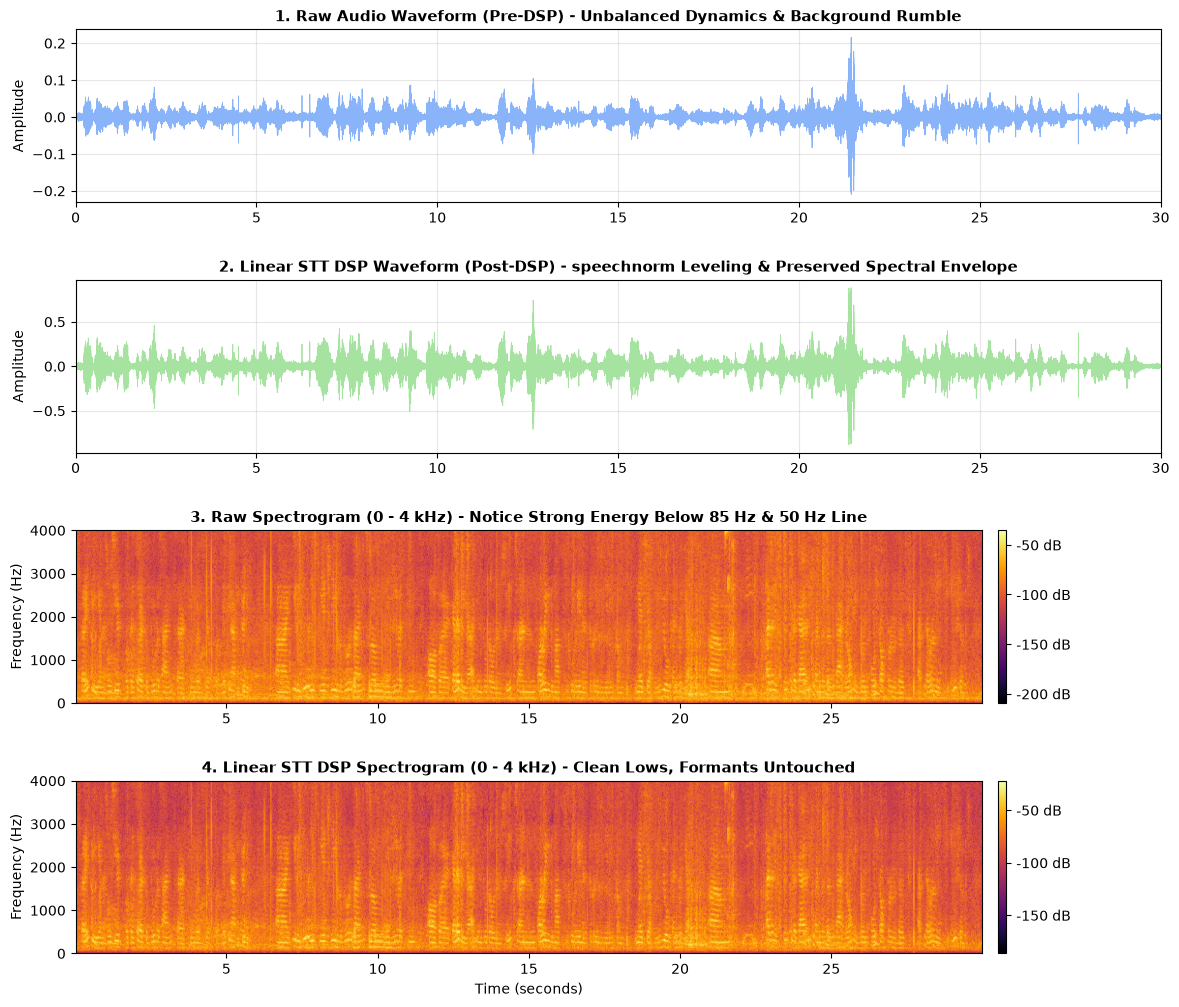

📊 Comparison analysis plot saved to: dsp_comparison_analysis.png


In [27]:
# Helper function to read raw PCM audio into numpy array
def load_wav_pcm(filepath: Path):
    with wave.open(str(filepath), 'rb') as wf:
        n_channels = wf.getnchannels()
        sampwidth = wf.getsampwidth()
        framerate = wf.getframerate()
        n_frames = wf.getnframes()
        raw_bytes = wf.readframes(n_frames)
        
        if sampwidth == 2:
            dtype = np.int16
        else:
            raise ValueError(f"Unsupported sample width: {sampwidth}")
            
        audio_data = np.frombuffer(raw_bytes, dtype=dtype).astype(np.float32)
        if n_channels > 1:
            audio_data = audio_data.reshape(-1, n_channels)[:, 0]  # Take channel 0
        audio_data = audio_data / 32768.0  # Normalize to [-1.0, 1.0]
        return audio_data, framerate

raw_sig, raw_rate = load_wav_pcm(RAW_INPUT_FILE)
dsp_sig, dsp_rate = load_wav_pcm(DSP_CONDITIONED_FILE)

# Limit plot to first 30 seconds for crisp visual resolution
plot_dur = min(30.0, raw_duration)
raw_plot_sig = raw_sig[:int(plot_dur * raw_rate)]
dsp_plot_sig = dsp_sig[:int(plot_dur * dsp_rate)]

time_raw = np.linspace(0, len(raw_plot_sig) / raw_rate, len(raw_plot_sig))
time_dsp = np.linspace(0, len(dsp_plot_sig) / dsp_rate, len(dsp_plot_sig))

# Plot comparison
fig, axs = plt.subplots(4, 1, figsize=(14, 12), gridspec_kw={'hspace': 0.45})

# 1. Raw Waveform
axs[0].plot(time_raw, raw_plot_sig, color='#89b4fa', lw=0.6)
axs[0].set_title("1. Raw Audio Waveform (Pre-DSP) - Unbalanced Dynamics & Background Rumble", fontsize=11, fontweight='bold')
axs[0].set_ylabel("Amplitude")
axs[0].set_xlim(0, plot_dur)
axs[0].grid(True, alpha=0.3)

# 2. DSP Conditioned Waveform
axs[1].plot(time_dsp, dsp_plot_sig, color='#a6e3a1', lw=0.6)
axs[1].set_title("2. Linear STT DSP Waveform (Post-DSP) - speechnorm Leveling & Preserved Spectral Envelope", fontsize=11, fontweight='bold')
axs[1].set_ylabel("Amplitude")
axs[1].set_xlim(0, plot_dur)
axs[1].grid(True, alpha=0.3)

# 3. Raw Spectrogram
Pxx_raw, freqs_raw, bins_raw, im_raw = axs[2].specgram(raw_plot_sig, NFFT=1024, Fs=raw_rate, noverlap=512, cmap='inferno')
axs[2].set_title("3. Raw Spectrogram (0 - 4 kHz) - Notice Strong Energy Below 85 Hz & 50 Hz Line", fontsize=11, fontweight='bold')
axs[2].set_ylabel("Frequency (Hz)")
axs[2].set_ylim(0, 4000)
fig.colorbar(im_raw, ax=axs[2], format='%+2.0f dB', pad=0.015)

# 4. DSP Spectrogram
Pxx_dsp, freqs_dsp, bins_dsp, im_dsp = axs[3].specgram(dsp_plot_sig, NFFT=1024, Fs=dsp_rate, noverlap=512, cmap='inferno')
axs[3].set_title("4. Linear STT DSP Spectrogram (0 - 4 kHz) - Clean Lows, Formants Untouched", fontsize=11, fontweight='bold')
axs[3].set_xlabel("Time (seconds)")
axs[3].set_ylabel("Frequency (Hz)")
axs[3].set_ylim(0, 4000)
fig.colorbar(im_dsp, ax=axs[3], format='%+2.0f dB', pad=0.015)

comparison_plot_path = RESULT_DIR / "dsp_comparison_analysis.png"
plt.savefig(comparison_plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"\U0001f4ca Comparison analysis plot saved to: {comparison_plot_path.name}")

In [28]:
# Quantitative Metrics Calculation
def calculate_metrics(sig, rate):
    rms = np.sqrt(np.mean(sig**2))
    rms_db = 20 * np.log10(rms + 1e-9)
    peak = np.max(np.abs(sig))
    peak_db = 20 * np.log10(peak + 1e-9)
    
    # Measure sub-85Hz rumble energy via FFT
    fft_vals = np.abs(np.fft.rfft(sig))
    fft_freqs = np.fft.rfftfreq(len(sig), 1.0 / rate)
    sub85_mask = fft_freqs < 85.0
    sub85_energy = np.sum(fft_vals[sub85_mask]**2)
    total_energy = np.sum(fft_vals**2) + 1e-9
    sub85_ratio_db = 10 * np.log10((sub85_energy / total_energy) + 1e-9)
    
    return {
        "rms_db": rms_db,
        "peak_db": peak_db,
        "sub85_ratio_db": sub85_ratio_db
    }

raw_metrics = calculate_metrics(raw_sig, raw_rate)
dsp_metrics = calculate_metrics(dsp_sig, dsp_rate)
rumble_reduction_db = raw_metrics["sub85_ratio_db"] - dsp_metrics["sub85_ratio_db"]

print("=" * 70)
print("              LAZY NOTE PIPELINE: WHAT DID WE GET?              ")
print("=" * 70)
print(f"Pipeline Stage Timings:")
print(f"  \u2022 Network Upload Simulation: {upload_duration:.1f} ms")
print(f"  \u2022 Master Remux (binary+copy): {remux_duration:.1f} ms")
print(f"  \u2022 Linear STT DSP Chain:          {dsp_duration:.1f} ms")
print(f"  \u2022 Silero VAD Compaction:     {vad_duration:.1f} ms")
print(f"  \u2022 Total Pipeline Run Time:   {upload_duration + remux_duration + dsp_duration + vad_duration:.1f} ms")
print("-" * 70)
print("Acoustic Signal Characteristics:")
print(f"  {'Metric':<28} | {'Raw Input':<16} | {'DSP Conditioned':<16} | {'Delta':<12}")
print(f"  {'-'*28} | {'-'*16} | {'-'*16} | {'-'*12}")
print(f"  {'Duration':<28} | {raw_duration:<13.2f} s | {dsp_duration_sec:<13.2f} s | {abs(raw_duration - dsp_duration_sec):<10.4f} s")
print(f"  {'RMS Level':<28} | {raw_metrics['rms_db']:<13.2f} dB| {dsp_metrics['rms_db']:<13.2f} dB| {dsp_metrics['rms_db'] - raw_metrics['rms_db']:<+10.2f} dB")
print(f"  {'Peak Level':<28} | {raw_metrics['peak_db']:<13.2f} dB| {dsp_metrics['peak_db']:<13.2f} dB| {dsp_metrics['peak_db'] - raw_metrics['peak_db']:<+10.2f} dB")
print(f"  {'Sub-85Hz Rumble Energy':<28} | {raw_metrics['sub85_ratio_db']:<13.2f} dB| {dsp_metrics['sub85_ratio_db']:<13.2f} dB| -{rumble_reduction_db:<9.2f} dB")
print("=" * 70)
print(f"\u2728 Verdict: Sub-85Hz noise attenuated by {rumble_reduction_db:.2f} dB while voice levels are leveled to {dsp_metrics['rms_db']:.2f} dB RMS.")
print(f"   VAD removed {vad_saved_pct:.1f}% dead silence ({orig_total_ms/1000:.1f}s -> {compacted_total_ms/1000:.1f}s) with a TimestampOffsetMap; ready for STT.")

              LAZY NOTE PIPELINE: WHAT DID WE GET?              
Pipeline Stage Timings:
  • Network Upload Simulation: 157.1 ms
  • Master Remux (binary+copy): 117.9 ms
  • Linear STT DSP Chain:          1073.2 ms
  • Silero VAD Compaction:     34568.4 ms
  • Total Pipeline Run Time:   35916.6 ms
----------------------------------------------------------------------
Acoustic Signal Characteristics:
  Metric                       | Raw Input        | DSP Conditioned  | Delta       
  ---------------------------- | ---------------- | ---------------- | ------------
  Duration                     | 60.00         s | 60.00         s | 0.0000     s
  RMS Level                    | -36.72        dB| -22.71        dB| +14.00     dB
  Peak Level                   | -10.21        dB| -0.44         dB| +9.77      dB
  Sub-85Hz Rumble Energy       | -24.85        dB| -31.47        dB| -6.62      dB
✨ Verdict: Sub-85Hz noise attenuated by 6.62 dB while voice levels are leveled to -22.71 dB RMS.
 

## 7. Next Steps & Architecture Continuity

This notebook now demonstrates:
1. **Realistic transport:** byte-level WebM/Opus chunks with only `chunk_0000` carrying the header, verified by checksum + sequence, then reassembled by binary concatenation and a lossless `-c copy` remux.
2. **Deterministic conditioning:** a linear 6-stage FFmpeg chain, with no pitch tracking and no formant boosting.
3. **VAD compaction:** Silero removes silences > 2.5 s and the `TimestampOffsetMap` preserves original wall-clock timestamps for ~10-minute STT slices.

**Not yet covered:** a downstream WER / technical-term recall comparison (raw master vs. DSP + VAD) on the real STT provider. Acoustic metrics such as RMS or rumble ratio do not guarantee better transcription accuracy.

All outputs are in `backend/notebooks/result/pipeline_test/`.
